In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge,Lasso,ElasticNet

DATA_PATH = "../dataset/house_price_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isna().sum())

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

for col in numeric_cols:
    if col not in ["House_ID", "Price"]:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277.0
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512.0
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806.0
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776.0
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975.0



Missing values:
 House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64
House_ID                      0
Area_sqft                     0
Bedrooms                      0
Bathrooms                     0
Floors                        0
Year_Built                    0
Location                      0
Furnishing_Status             0
Parking_Available             0
Garage_Count                  0
Lot_Size_sqft      

In [2]:
X = df.drop(columns=["House_ID", "Price"])

print("Independent Features:")
display(X.head())

print("Dataset Shape:", X.shape)

Independent Features:


,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated
0,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no
1,2646.2,2.0,5.0,2.0,2005,riverside,Semi Furnished,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y
2,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,6.48,Yes,no
3,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes
4,3227.0,3.0,5.0,2.0,1995,Lake side,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes


Dataset Shape: (15025, 16)


In [3]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']

Categorical Features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']


In [4]:
numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_processed = preprocessor.fit_transform(X)

if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("Processed Dataset Shape:", X_processed.shape)

Processed Dataset Shape: (15025, 80)


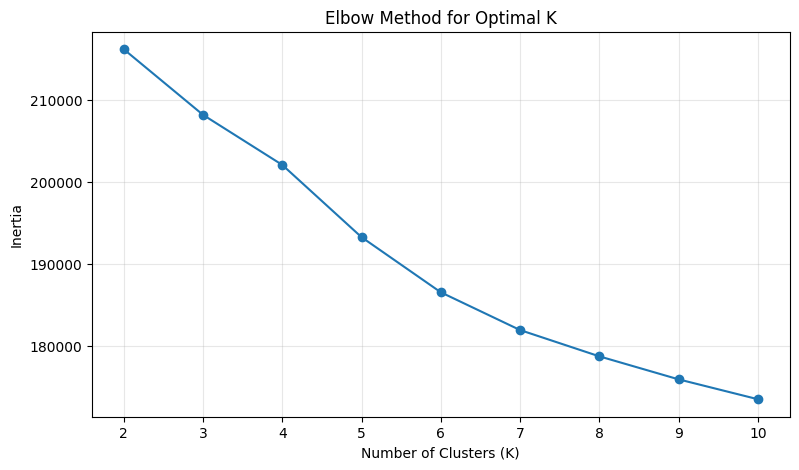

In [5]:
inertia = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_processed)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(K, inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.grid(alpha=0.3)
plt.show()

In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_processed)

df["Cluster"] = clusters

print("K-means Clustering Completed Successfully!")
print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

K-means Clustering Completed Successfully!

Cluster Distribution:
Cluster
0    1958
1    6381
2    6686
Name: count, dtype: int64


In [7]:
score = silhouette_score(X_processed, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.05528156950356585


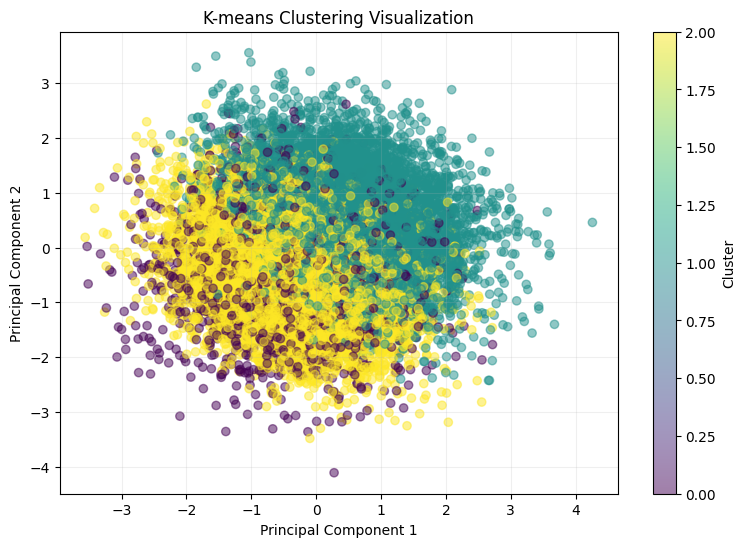

In [8]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_processed)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-means Clustering Visualization")

plt.colorbar(scatter, label="Cluster")

plt.grid(alpha=0.2)
plt.show()

In [9]:
cluster_summary = df.groupby("Cluster").agg({
    "Area_sqft": "mean",
    "Bedrooms": "mean",
    "Bathrooms": "mean",
    "Floors": "mean",
    "Garage_Count": "mean",
    "Price": "mean"
})

display(cluster_summary.round(2))

,Area_sqft,Bedrooms,Bathrooms,Floors,Garage_Count,Price
Cluster,,,,,,
0,2180.99,3.55,3.10,1.74,1.42,351978.31
1,2196.37,3.52,3.07,1.73,2.51,375915.57
2,2195.74,3.52,3.05,1.72,0.50,367525.88


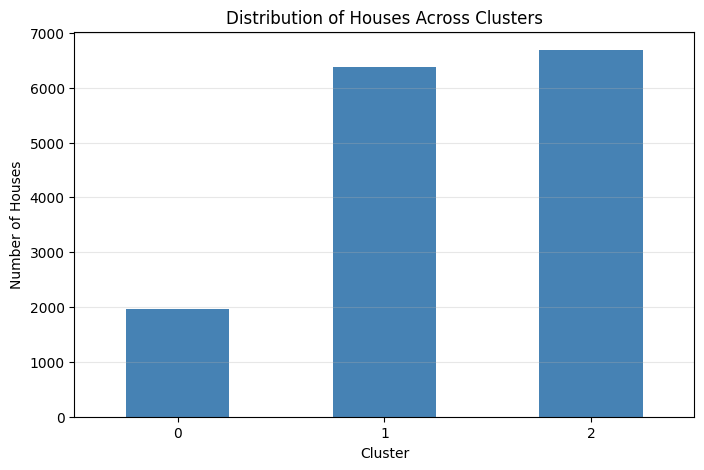

In [10]:
plt.figure(figsize=(8, 5))

df["Cluster"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.xlabel("Cluster")
plt.ylabel("Number of Houses")
plt.title("Distribution of Houses Across Clusters")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()